# Assignment: Consumer Credit Scoring from Multi-source Data
**Course:** Machine Learning Engineering (MLE501)  
**Class:** MSA41HCM - Fall2026  
**Student:** Trần Tiến Cường  
**Email:** cuong26ms23348@fsb.edu.vn  
**Objective:** Build an explainable Logistic Regression scorecard to predict default probability (`vo_no = 1`) at application submission by integrating 6 source databases under strict Point-in-time constraints.

---
### Notebook Outline:
1. **Exploratory Data Analysis (EDA) & Business Context**
2. **Multi-Source Data Integration & Point-in-Time Alignment**
3. **Cross-Source Feature Engineering**
4. **Model Training & Source-Level Ablation Study (Stratified 5-Fold CV)**
5. **Ablation Curve Visualization**
6. **Operational Analysis: Decision Cut-offs & Test Predictions Export**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import RobustScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import roc_auc_score, confusion_matrix

# Display & Output settings
pd.set_option('display.max_columns', None)
os.makedirs('../outputs', exist_ok=True)
os.makedirs('../report/figures', exist_ok=True)

## 1. Exploratory Data Analysis (EDA) & Business Context
The assignment provides 7 CSV files across 6 operational systems. The unit of observation is a single loan application (`ma_ho_so`).
- `applications_train.csv` (16,046 labeled records)
- `applications_test.csv` (3,954 unlabeled records for grading)
- Ancillary systems: Customers CRM, Dealerships, Credit Bureau (CIC), Repayment History, Payroll.

In [2]:
# Load raw data sources
train_raw = pd.read_csv('../data/applications_train.csv')
test_raw = pd.read_csv('../data/applications_test.csv')
cust_raw = pd.read_csv('../data/customers.csv')
dealers_raw = pd.read_csv('../data/dealers.csv')
bureau_raw = pd.read_csv('../data/credit_bureau.csv')
repay_raw = pd.read_csv('../data/repayment_history.csv')
payroll_raw = pd.read_csv('../data/payroll.csv')

print(f"Applications Train: {train_raw.shape}")
print(f"Applications Test:  {test_raw.shape}")
print(f"Customers (CRM):    {cust_raw.shape}")
print(f"Dealers:            {dealers_raw.shape}")
print(f"Credit Bureau:      {bureau_raw.shape}")
print(f"Repayment History:  {repay_raw.shape}")
print(f"Payroll:            {payroll_raw.shape}")

baseline_bad_rate = train_raw['vo_no'].mean()
print(f"\nBaseline Default Rate (vo_no=1): {baseline_bad_rate:.2%} ({train_raw['vo_no'].sum():,}/{len(train_raw):,} records)")

Applications Train: (16046, 14)
Applications Test:  (3954, 13)
Customers (CRM):    (20000, 7)
Dealers:            (300, 5)
Credit Bureau:      (20300, 9)
Repayment History:  (179265, 7)
Payroll:            (259416, 3)

Baseline Default Rate (vo_no=1): 11.86% (1,903/16,046 records)


## 2. Multi-Source Data Integration & Point-in-Time Alignment
- **Credit Bureau:** 1-to-N on `ma_ho_so`, aggregated to 1 row per application (total external debt, monthly obligations, max risk group, 12M overdue count).
- **Repayment History:** 1-to-N on `ma_khach_hang`, all concluded before Dec 2023 (naturally leak-free). Aggregated to max DPD, late payment counts, underpayment frequency.
- **Payroll:** Filtered strictly to `thang <= application_month` to guard against forward look-ahead bias (data leakage).

In [3]:
# Tag train and test sets to maintain consistent structure
train_raw['is_test'] = 0
test_raw['is_test'] = 1
test_raw['vo_no'] = np.nan
apps = pd.concat([train_raw, test_raw], ignore_index=True)

# 1. Aggregate Credit Bureau (1-to-N on ma_ho_so)
bureau_agg = bureau_raw.groupby('ma_ho_so').agg(
    bureau_so_khoan_vay=('du_no_hien_tai', 'count'),
    bureau_tong_du_no=('du_no_hien_tai', 'sum'),
    bureau_tong_tra_hang_thang=('tra_hang_thang', 'sum'),
    bureau_nhom_no_max=('nhom_no_cao_nhat', 'max'),
    bureau_tong_qua_han_12t=('so_lan_qua_han_12t', 'sum')
).reset_index()

apps = apps.merge(bureau_agg, on='ma_ho_so', how='left')
apps['has_bureau'] = apps['bureau_so_khoan_vay'].notnull().astype(int)
for col in ['bureau_so_khoan_vay', 'bureau_tong_du_no', 'bureau_tong_tra_hang_thang', 'bureau_nhom_no_max', 'bureau_tong_qua_han_12t']:
    apps[col] = apps[col].fillna(0)

# 2. Aggregate Repayment History (1-to-N on ma_khach_hang)
repay_raw['ngay_den_han'] = pd.to_datetime(repay_raw['ngay_den_han'])
repay_raw['ngay_thanh_toan'] = pd.to_datetime(repay_raw['ngay_thanh_toan'])
repay_raw['dpd'] = (repay_raw['ngay_thanh_toan'] - repay_raw['ngay_den_han']).dt.days
repay_raw['dpd_duong'] = repay_raw['dpd'].clip(lower=0)
repay_raw['is_late'] = (repay_raw['dpd'] > 0).astype(int)
repay_raw['is_underpaid'] = (repay_raw['so_tien_da_tra'] < repay_raw['so_tien_phai_tra']).astype(int)

repay_agg = repay_raw.groupby('ma_khach_hang').agg(
    repay_so_ky_vay=('ky_thu', 'count'),
    repay_dpd_max=('dpd_duong', 'max'),
    repay_dpd_mean=('dpd_duong', 'mean'),
    repay_so_lan_tre=('is_late', 'sum'),
    repay_ty_le_tre=('is_late', 'mean'),
    repay_so_lan_thieu=('is_underpaid', 'sum'),
    repay_ty_le_thieu=('is_underpaid', 'mean')
).reset_index()

apps = apps.merge(repay_agg, on='ma_khach_hang', how='left')
apps['is_existing_cust'] = apps['repay_so_ky_vay'].notnull().astype(int)
for col in ['repay_so_ky_vay', 'repay_dpd_max', 'repay_dpd_mean', 'repay_so_lan_tre', 'repay_ty_le_tre', 'repay_so_lan_thieu', 'repay_ty_le_thieu']:
    apps[col] = apps[col].fillna(0)

# 3. Aggregate Payroll with Point-in-Time filter (thang <= thang_nop)
apps['thang_nop'] = apps['ngay_nop'].str.slice(0, 7)
payroll_merged = payroll_raw.merge(apps[['ma_ho_so', 'ma_khach_hang', 'thang_nop']], on='ma_khach_hang', how='inner')
payroll_valid = payroll_merged[payroll_merged['thang'] <= payroll_merged['thang_nop']].sort_values(['ma_ho_so', 'thang'])

payroll_agg = payroll_valid.groupby('ma_ho_so').agg(
    payroll_so_thang=('luong_thuc_nhan', 'count'),
    payroll_luong_gan_nhat=('luong_thuc_nhan', 'last'),
    payroll_luong_mean=('luong_thuc_nhan', 'mean'),
    payroll_luong_std=('luong_thuc_nhan', 'std')
).reset_index()

apps = apps.merge(payroll_agg, on='ma_ho_so', how='left')
apps['has_payroll'] = apps['payroll_so_thang'].notnull().astype(int)
apps['payroll_luong_std'] = apps['payroll_luong_std'].fillna(0)

# 4. Merge CRM & Dealers
apps = apps.merge(cust_raw, on='ma_khach_hang', how='left')
dealers_renamed = dealers_raw.rename(columns={'tinh': 'tinh_dai_ly', 'loai_dai_ly': 'loai_hang_dai_ly'})
apps = apps.merge(dealers_renamed, on='ma_dai_ly', how='left')

print(f"Total applications after integration: {len(apps):,} (Exact match: 20,000 rows)")

Total applications after integration: 20,000 (Exact match: 20,000 rows)


## 3. Cross-Source Feature Engineering
Engineering the mandatory cross-source signals:
1. **Total Debt-to-Income (DTI):** `(New Monthly Payment + External Bureau Monthly Debt) / Estimated Monthly Income`
2. **Income Exaggeration Factor:** `1 - (Latest Verified Payroll Salary / Self-Declared Stated Income)`

In [4]:
# Customer age at application date
apps['tuoi'] = ((pd.to_datetime(apps['ngay_nop']) - pd.to_datetime(apps['ngay_sinh'])).dt.days / 365.25).round(1)

# Application loan metrics
apps['ty_le_tra_truoc'] = apps['tra_truoc'] / apps['gia_tri_hang']
apps['ap_luc_tra_gop_tnf'] = apps['tra_gop_thang'] / apps['thu_nhap_khai_bao']

# Estimated income: Prefer verified payroll salary, fallback to stated income
apps['thu_nhap_uoc_tinh'] = np.where(apps['has_payroll'] == 1,
                                     apps['payroll_luong_gan_nhat'],
                                     apps['thu_nhap_khai_bao'])

# Mandatory Cross-Feature 1: Total DTI
apps['dti_tong'] = (apps['tra_gop_thang'] + apps['bureau_tong_tra_hang_thang']) / apps['thu_nhap_uoc_tinh']

# Mandatory Cross-Feature 2: Income Exaggeration
apps['do_phong_dai_thu_nhap'] = np.where(
    apps['has_payroll'] == 1,
    1.0 - (apps['payroll_luong_gan_nhat'] / apps['thu_nhap_khai_bao']),
    0.0
)

# Split back to processed Train and Test sets
train_df = apps[apps['is_test'] == 0].drop(columns=['is_test']).copy()
test_df = apps[apps['is_test'] == 1].drop(columns=['is_test', 'vo_no']).copy()

print(f"Processed Train Shape: {train_df.shape}")
print(f"Processed Test Shape:  {test_df.shape}")

Processed Train Shape: (16046, 50)
Processed Test Shape:  (3954, 49)


## 4. Model Training & Source-Level Ablation Study
We train an $L_2$-regularized **Logistic Regression** pipeline evaluated with **Stratified 5-Fold Cross-Validation** across the 5 cumulative data stages.

In [5]:
def calculate_ks(y_true, y_prob):
    """Calculate Kolmogorov-Smirnov (KS) statistic"""
    df = pd.DataFrame({'y_true': y_true, 'y_prob': y_prob}).sort_values(by='y_prob', ascending=False).reset_index(drop=True)
    df['bad'] = df['y_true']
    df['good'] = 1 - df['y_true']
    df['cum_bad'] = df['bad'].cumsum() / df['bad'].sum()
    df['cum_good'] = df['good'].cumsum() / df['good'].sum()
    return (df['cum_bad'] - df['cum_good']).abs().max()

# 5 Cumulative stages for ablation study
stages = [
    ("1. Application Only", 
     ['gia_tri_hang', 'tra_truoc', 'so_tien_vay', 'ky_han_thang', 'lai_suat_nam', 'tra_gop_thang', 'thu_nhap_khai_bao'],
     ['loai_san_pham', 'nghe_nghiep']),
    ("2. + Customer & Dealer",
     ['gia_tri_hang', 'tra_truoc', 'so_tien_vay', 'ky_han_thang', 'lai_suat_nam', 'tra_gop_thang', 'thu_nhap_khai_bao',
      'so_nguoi_phu_thuoc', 'so_nam_cu_tru', 'so_nam_hop_tac', 'tuoi', 'ty_le_tra_truoc', 'ap_luc_tra_gop_tnf'],
     ['loai_san_pham', 'nghe_nghiep', 'tinh', 'tinh_trang_hon_nhan', 'loai_nha_o', 'quy_mo', 'loai_hang_dai_ly']),
    ("3. + Credit Bureau (CIC)",
     ['gia_tri_hang', 'tra_truoc', 'so_tien_vay', 'ky_han_thang', 'lai_suat_nam', 'tra_gop_thang', 'thu_nhap_khai_bao',
      'so_nguoi_phu_thuoc', 'so_nam_cu_tru', 'so_nam_hop_tac', 'tuoi', 'ty_le_tra_truoc', 'ap_luc_tra_gop_tnf',
      'has_bureau', 'bureau_so_khoan_vay', 'bureau_tong_du_no', 'bureau_tong_tra_hang_thang', 'bureau_nhom_no_max', 'bureau_tong_qua_han_12t'],
     ['loai_san_pham', 'nghe_nghiep', 'tinh', 'tinh_trang_hon_nhan', 'loai_nha_o', 'quy_mo', 'loai_hang_dai_ly']),
    ("4. + Repayment History",
     ['gia_tri_hang', 'tra_truoc', 'so_tien_vay', 'ky_han_thang', 'lai_suat_nam', 'tra_gop_thang', 'thu_nhap_khai_bao',
      'so_nguoi_phu_thuoc', 'so_nam_cu_tru', 'so_nam_hop_tac', 'tuoi', 'ty_le_tra_truoc', 'ap_luc_tra_gop_tnf',
      'has_bureau', 'bureau_so_khoan_vay', 'bureau_tong_du_no', 'bureau_tong_tra_hang_thang', 'bureau_nhom_no_max', 'bureau_tong_qua_han_12t',
      'is_existing_cust', 'repay_so_ky_vay', 'repay_dpd_max', 'repay_dpd_mean', 'repay_so_lan_tre', 'repay_ty_le_tre', 'repay_so_lan_thieu', 'repay_ty_le_thieu'],
     ['loai_san_pham', 'nghe_nghiep', 'tinh', 'tinh_trang_hon_nhan', 'loai_nha_o', 'quy_mo', 'loai_hang_dai_ly']),
    ("5. + Payroll & Cross Features",
     ['gia_tri_hang', 'tra_truoc', 'so_tien_vay', 'ky_han_thang', 'lai_suat_nam', 'tra_gop_thang', 'thu_nhap_khai_bao',
      'so_nguoi_phu_thuoc', 'so_nam_cu_tru', 'so_nam_hop_tac', 'tuoi', 'ty_le_tra_truoc', 'ap_luc_tra_gop_tnf',
      'has_bureau', 'bureau_so_khoan_vay', 'bureau_tong_du_no', 'bureau_tong_tra_hang_thang', 'bureau_nhom_no_max', 'bureau_tong_qua_han_12t',
      'is_existing_cust', 'repay_so_ky_vay', 'repay_dpd_max', 'repay_dpd_mean', 'repay_so_lan_tre', 'repay_ty_le_tre', 'repay_so_lan_thieu', 'repay_ty_le_thieu',
      'has_payroll', 'payroll_so_thang', 'payroll_luong_gan_nhat', 'payroll_luong_mean', 'payroll_luong_std', 'dti_tong', 'do_phong_dai_thu_nhap'],
     ['loai_san_pham', 'nghe_nghiep', 'tinh', 'tinh_trang_hon_nhan', 'loai_nha_o', 'quy_mo', 'loai_hang_dai_ly'])
]

y_train = train_df['vo_no'].values
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

ablation_data = []
final_oof = np.zeros(len(train_df))
final_test_pred = np.zeros(len(test_df))

for idx, (name, num_f, cat_f) in enumerate(stages):
    preprocessor = ColumnTransformer([
        ('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', RobustScaler())]), num_f),
        ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), cat_f)
    ])
    clf = Pipeline([('prep', preprocessor), ('lr', LogisticRegression(C=0.1, max_iter=1000, random_state=42))])
    
    oof = np.zeros(len(train_df))
    test_p = np.zeros(len(test_df))
    
    for tr_idx, val_idx in cv.split(train_df, y_train):
        clf.fit(train_df.iloc[tr_idx], y_train[tr_idx])
        oof[val_idx] = clf.predict_proba(train_df.iloc[val_idx])[:, 1]
        test_p += clf.predict_proba(test_df)[:, 1] / 5.0
        
    auc = roc_auc_score(y_train, oof)
    ks = calculate_ks(y_train, oof)
    ablation_data.append({'Stage': name, 'Num_Features': len(num_f)+len(cat_f), 'AUC_5Fold': round(auc, 4), 'KS': round(ks, 4)})
    print(f"{name:30s} | AUC: {auc:.4f} | KS: {ks:.4f}")
    
    if idx == len(stages) - 1:
        final_oof = oof
        final_test_pred = test_p

ablation_df = pd.DataFrame(ablation_data)
ablation_df['Delta_AUC'] = ablation_df['AUC_5Fold'].diff().fillna(0).round(4)
print("\n--- ABLATION STUDY SUMMARY TABLE ---")
print(ablation_df)

1. Application Only            | AUC: 0.6567 | KS: 0.2334


2. + Customer & Dealer         | AUC: 0.6838 | KS: 0.2686


3. + Credit Bureau (CIC)       | AUC: 0.7761 | KS: 0.4131


4. + Repayment History         | AUC: 0.8003 | KS: 0.4510


5. + Payroll & Cross Features  | AUC: 0.8262 | KS: 0.4972

--- ABLATION STUDY SUMMARY TABLE ---
                           Stage  Num_Features  AUC_5Fold      KS  Delta_AUC
0            1. Application Only             9     0.6567  0.2334     0.0000
1         2. + Customer & Dealer            20     0.6838  0.2686     0.0271
2       3. + Credit Bureau (CIC)            26     0.7761  0.4131     0.0923
3         4. + Repayment History            34     0.8003  0.4510     0.0242
4  5. + Payroll & Cross Features            41     0.8262  0.4972     0.0259


## 5. Ablation Curve Visualization
Plotting the cumulative ROC-AUC gains across the five data integration tiers.

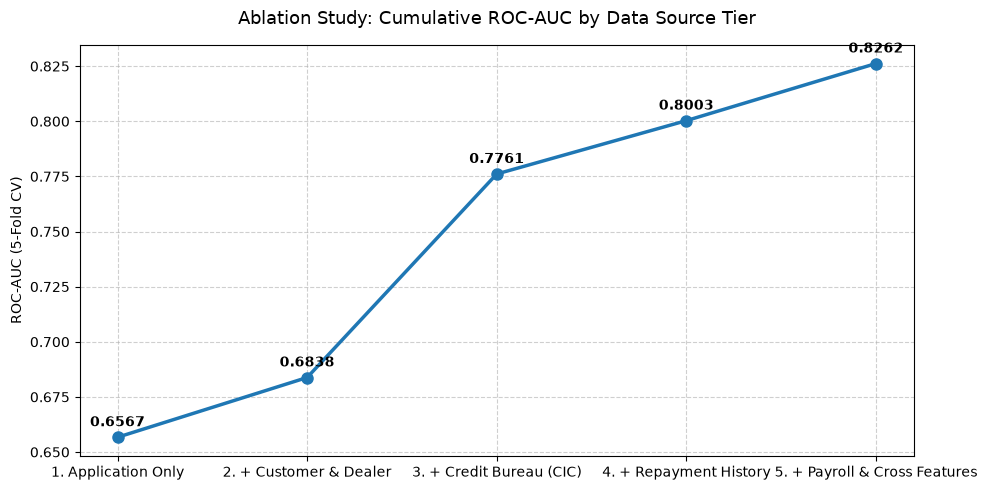

In [6]:
plt.figure(figsize=(10, 5))
plt.plot(ablation_df['Stage'], ablation_df['AUC_5Fold'], marker='o', color='#1f77b4', linewidth=2.5, markersize=8)
for i, txt in enumerate(ablation_df['AUC_5Fold']):
    plt.annotate(f"{txt:.4f}", (ablation_df['Stage'][i], ablation_df['AUC_5Fold'][i] + 0.005), ha='center', fontweight='bold')
plt.title('Ablation Study: Cumulative ROC-AUC by Data Source Tier', fontsize=13, pad=15)
plt.ylabel('ROC-AUC (5-Fold CV)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

## 6. Operational Analysis & Export Predictions
Analyzing confusion matrices across candidate operational cut-offs to evaluate the trade-off between **Approval Rate** and **Post-Approval Bad Rate**.

In [7]:
print("=== CONFUSION MATRIX & TRADE-OFFS BY CUT-OFF THRESHOLD ===")
cutoffs = [0.10, 0.15, 0.20, 0.30]
for th in cutoffs:
    pred_bad = (final_oof >= th).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_train, pred_bad).ravel()
    app_rate = (pred_bad == 0).mean()
    bad_in_app = y_train[pred_bad == 0].mean()
    print(f"Cut-off {th:.2f} | Approval Rate: {app_rate:5.1%} | Post-Approval Bad Rate: {bad_in_app:5.2%} | Defaulters Caught: {tp:,} / {tp+fn:,}")

# Export predictions file for test submission
submission = pd.DataFrame({
    'ma_ho_so': test_df['ma_ho_so'],
    'xac_suat_vo_no': final_test_pred
})
submission.to_csv('../outputs/du_doan.csv', index=False)
print(f"\n-> Successfully exported outputs/du_doan.csv ({len(submission):,} rows).")
print(submission.head())

=== CONFUSION MATRIX & TRADE-OFFS BY CUT-OFF THRESHOLD ===
Cut-off 0.10 | Approval Rate: 65.6% | Post-Approval Bad Rate: 3.96% | Defaulters Caught: 1,486 / 1,903
Cut-off 0.15 | Approval Rate: 76.6% | Post-Approval Bad Rate: 5.34% | Defaulters Caught: 1,246 / 1,903
Cut-off 0.20 | Approval Rate: 83.2% | Post-Approval Bad Rate: 6.36% | Defaulters Caught: 1,054 / 1,903
Cut-off 0.30 | Approval Rate: 90.3% | Post-Approval Bad Rate: 7.68% | Defaulters Caught: 790 / 1,903

-> Successfully exported outputs/du_doan.csv (3,954 rows).
       ma_ho_so  xac_suat_vo_no
16046  HS000001        0.036773
16047  HS000003        0.006801
16048  HS000010        0.285389
16049  HS000011        0.345243
16050  HS000014        0.054299
